# Lab 4: Regularization

## Exercise: Regularization of German Credit Numeric example

* Vamos a aplicar las siguientes regularizaciones al ejemplo _German Credit_
  - _Early stopping_
  - Regularización de pesos
  - _Dropout_

### Cargamos el conjunto de datos

In [1]:
import keras
from keras import layers
import tensorflow as tf
import tensorflow_datasets as tfds
import os
import numpy as np
import random

#Fijamos la semilla para poder reproducir los resultados
seed=1234
os.environ['PYTHONHASHSEED']=str(seed)
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

I0000 00:00:1795015838.434687    4984 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795015838.482389    4984 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Cargamos el conjunto de datos
ds_train = tfds.load('german_credit_numeric', split='train[:40%]',  as_supervised=True).batch(128)
ds_val = tfds.load('german_credit_numeric', split='train[40%:50%]', as_supervised=True).batch(128)
ds_test = tfds.load('german_credit_numeric', split='train[50%:]', as_supervised=True).batch(128)

I0000 00:00:1795015843.275440    4984 gpu_device.cc:2038] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
E0000 00:00:1795015843.339081    4984 cuda_executor.cc:1435] [0] Failed to allocate device memory of 5.43GiB (5833228288 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:241
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:508

E0000 00:00:1795015843.342014    4984 cuda_executor.cc:1435] [0] Failed to allocate device memory of 4.89GiB (5249905152 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.c

In [3]:
#Indicamos la función de perdida, el algoritmo de optimización y la métrica para evaluar el rendimiento 
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

### Creamos un modelo `Sequential`

In [4]:
tamano_entrada = 24
h0_size = 20
h1_size = 10
h2_size = 5

#TODO - define el modelo Sequential
model = keras.Sequential(name='german_credit_reg')

#TODO - incluye la capa de entrada y las 3 capas del modelo Dense 
model.add(layers.Input(shape=(tamano_entrada,)))
model.add(layers.Dense(h0_size, activation='relu', name='hidden_0'))
model.add(layers.Dense(h1_size, activation='relu', name='hidden_1'))
model.add(layers.Dense(h2_size, activation='relu', name='hidden_2'))
model.add(layers.Dense(1, activation='sigmoid', name='output'))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_reg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_0 (Dense)                │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [5]:
#TODO - indicar los parametros del método compile
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [6]:
#Establecemos el número de epochs
num_epochs =  700

# Guardamos los pesos antes de entrenar, para poder resetear el modelo posteriormente y hacer comparativas.
pesos_preentrenamiento = model.get_weights()

#TODO - entrenar el modelo
history = model.fit(ds_train,
                    epochs=num_epochs,
                    validation_data=ds_val)

Epoch 1/700


/home/snesh/AP/ap/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795015845.593395    5142 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
I0000 00:00:1795015845.990448    4984 service.cc:155] XLA service 0x364d0300 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795015845.990476    4984 service.cc:171]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.9.0[576.80.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795015846.037156    4984 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRO

1/4 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - auc: 0.4138 - loss: 2.8578

I0000 00:00:1795015848.692350    4984 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - auc: 0.4124 - loss: 2.7253 - val_auc: 0.2995 - val_loss: 2.7827
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc: 0.4000 - loss: 2.0977 - val_auc: 0.2824 - val_loss: 2.1008
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.3913 - loss: 1.5756 - val_auc: 0.3129 - val_loss: 1.5331
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.3847 - loss: 1.1792 - val_auc: 0.3133 - val_loss: 1.1672
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.3839 - loss: 0.9236 - val_auc: 0.3264 - val_loss: 0.9264
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.3839 - loss: 0.7887 - val_auc: 0.3348 - val_loss: 0.8390
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.3893 - loss: 0.7301 - val_auc: 0.3429 - val_loss: 0.7868
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc: 0.4021 - loss: 0.6978 - val_auc: 0.3757 - val_loss: 0.7494
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.4332 - loss: 0.6802 - val_auc: 0.37

In [7]:
import matplotlib.pyplot as plt

# Nueva versión que imprime la gráfica sin puntos
# Si son muchos (700) una recta se ve de forma más clara
def plot_no_dots(train, validation, title):
    plt.clf()
    epochs = range(1, len(train) + 1)
    
    plt.plot(epochs, train, 'b-', label='Training ' + title)
    plt.plot(epochs, validation, 'r--', label='Validation '+ title) 

    plt.title('Training and validation ' + title)
    plt.xlabel('Epochs')
    plt.ylabel(title)
    plt.legend()
    plt.show()

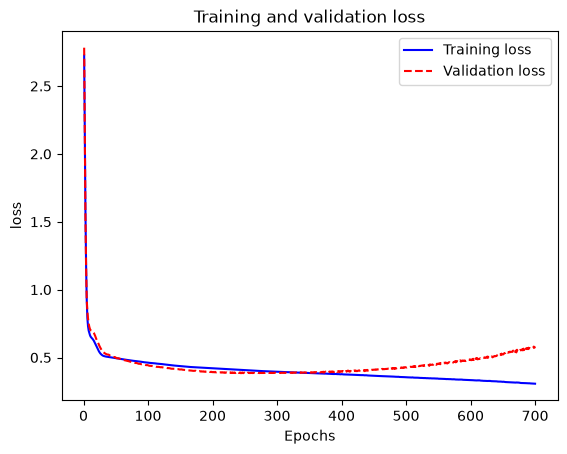

In [8]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [9]:
#TODO - llamar a evaluate, guardando el resultado
result = model.evaluate(ds_test)
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 464ms/step - auc: 0.7231 - loss: 0.8580
['loss', 'compile_metrics']
[0.8580042123794556, 0.7230623364448547]


### 4.7.3. Usamos _Early Stopping_

In [10]:
from keras.callbacks import EarlyStopping

# simple early stopping
#TODO- indica la medida a monitorizar, el modo y la paciencia
es = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=20
)

# Antes de entrenar, olvidamos el entrenamiento anterior restaurando los pesos iniciales
model.set_weights(pesos_preentrenamiento)

#TODO- indica el porcentaje de muestras que se usarán para validación
history = model.fit(ds_train,
                    epochs=num_epochs,
                    validation_data=ds_val,
                    callbacks=[es])

Epoch 1/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc: 0.4110 - loss: 2.5948 - val_auc: 0.2898 - val_loss: 1.7674
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc: 0.4041 - loss: 1.1056 - val_auc: 0.3095 - val_loss: 0.8453
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc: 0.3788 - loss: 0.7479 - val_auc: 0.2952 - val_loss: 0.7989
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - auc: 0.3451 - loss: 0.7652 - val_auc: 0.3726 - val_loss: 0.7581
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - auc: 0.3780 - loss: 0.7373 - val_auc: 0.4019 - val_loss: 0.7145
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - auc: 0.4686 - loss: 0.7036 - val_auc: 0.4524 - val_loss: 0.6918
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.5028 - loss: 0.6869 - val_auc: 0.5062 - val_loss: 0.6836
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.5048 - loss: 0.6798 - val_auc: 0.4929 - val_loss: 0.6804
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc: 0.5204 - loss: 0.6763 -

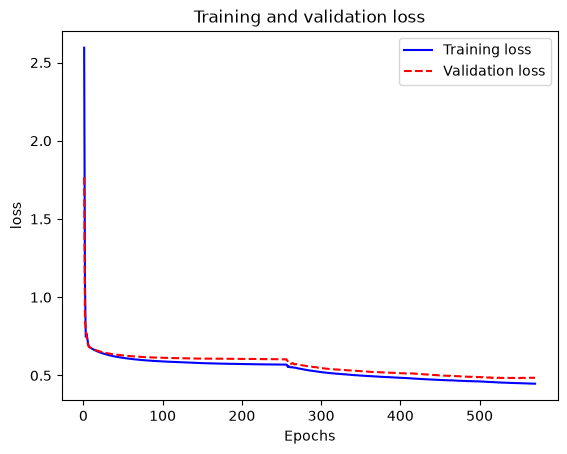

In [11]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [12]:
#TODO - llamar a evaluate
result = model.evaluate(ds_test) 
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - auc: 0.6169 - loss: 0.6283
['loss', 'compile_metrics']
[0.6283218860626221, 0.6169461011886597]


### 4.7.4. Usamos regularización de pesos

In [13]:
from tensorflow.keras.regularizers import l2
#from tensorflow.keras.regularizers import l1

tamano_entrada = 24
#TODO- Varía el valor de alpha para ajustar la regularización
alpha = 0.01
h0_size = 20
h1_size = 10
h2_size = 5

#TODO - define el modelo Sequential
model = keras.Sequential(name='german_credit_l2')
#TODO - incluye la capa de entrada
model.add(layers.Input(shape=(tamano_entrada,)))
#TODO - incluye las unidades de la primera capa Dense
model.add(layers.Dense(units=h0_size, kernel_regularizer=l2(alpha), activation='relu'))
#TODO - incluye el regularizador en las distintas capas
model.add(layers.Dense(units=h1_size, kernel_regularizer=l2(alpha), activation='relu'))
model.add(layers.Dense(units=h2_size, kernel_regularizer=l2(alpha), activation='relu'))
model.add(layers.Dense(units=1, activation='sigmoid', name='output'))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_l2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [14]:
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

In [15]:
#TODO - indicar los parametros del método compile
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [16]:
num_epochs = 700
#TODO - entrenar el modelo
history = model.fit(ds_train,
                    epochs=num_epochs,
                    validation_data=ds_val)

Epoch 1/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step - auc_1: 0.4102 - loss: 1.8904 - val_auc_1: 0.3236 - val_loss: 1.9857
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc_1: 0.4085 - loss: 1.6991 - val_auc_1: 0.3262 - val_loss: 1.7889
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc_1: 0.4138 - loss: 1.5293 - val_auc_1: 0.3355 - val_loss: 1.6065
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_1: 0.4232 - loss: 1.3742 - val_auc_1: 0.3555 - val_loss: 1.4375
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_1: 0.4293 - loss: 1.2379 - val_auc_1: 0.3802 - val_loss: 1.2846
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc_1: 0.4565 - loss: 1.1165 - val_auc_1: 0.4086 - val_loss: 1.1446
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_1: 0.5234 - loss: 1.0188 - val_auc_1: 0.4964 - val_loss: 1.0569
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc_1: 0.5769 - loss: 0.9773 - val_auc_1: 0.5638 - val_loss: 1.0229
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/st

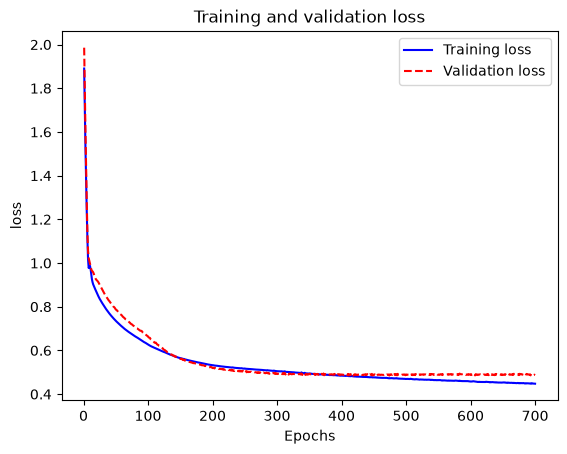

In [17]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [18]:
#TODO - llamar a evaluate
result = model.evaluate(ds_test)
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ -1s 68ms/step - auc_1: 0.7604 - loss: 0.6504    
['loss', 'compile_metrics']
[0.6503894925117493, 0.7604097723960876]


### 4.7.5. Usamos _Dropout_

In [19]:
#Indicamos la función de perdida, el algoritmo de optimización y la métrica para evaluar el rendimiento 
fn_perdida = keras.losses.BinaryCrossentropy()
optimizador = keras.optimizers.Adam(0.001)
metrica = keras.metrics.AUC()

In [20]:
tamano_entrada = 24
h0_size = 20
h1_size = 10
h2_size = 5

#TODO - define el modelo Sequential
model = keras.Sequential(name='german_credit_dropout')

#TODO - incluye la capa de entrada y las 3 capas Dense al modelo 
model.add(layers.Input(shape=(tamano_entrada,)))
model.add(layers.Dense(h0_size, activation='relu'))
model.add(layers.Dropout(0.2))

#TODO - incluir el resto de capas Dense y Dropout
model.add(layers.Dense(h1_size, activation='relu'))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(h2_size, activation='relu'))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(1, activation='sigmoid', name='output'))

#Construimos el modelo y mostramos 
model.build()
print(model.summary())

Model: "german_credit_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 20)             │           500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

None


In [21]:
#TODO - indicar los parametros del método compile
model.compile(loss=fn_perdida,
              optimizer=optimizador,
              metrics=[metrica])

In [22]:
num_epochs = 700
#TODO - entrenar el modelo
history = model.fit(ds_train,
                    epochs=num_epochs,
                    validation_data=ds_val)

Epoch 1/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 962ms/step - auc_2: 0.5194 - loss: 2.6260WARNING:tensorflow:5 out of the last 3505 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x7a45e79f2f20> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - auc_2: 0.5194 - loss: 2.6260 - val_auc_2: 0.6240 - val_loss: 1.6031
Epoch 2/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc_2: 0.5067 - loss: 2.0707 - val_auc_2: 0.6148 - val_loss: 1.1757
Epoch 3/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc_2: 0.5046 - loss: 1.7843 - val_auc_2: 0.6190 - val_loss: 0.8955
Epoch 4/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_2: 0.5354 - loss: 1.3316 - val_auc_2: 0.6548 - val_loss: 0.7335
Epoch 5/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_2: 0.5671 - loss: 1.1607 - val_auc_2: 0.6664 - val_loss: 0.6773
Epoch 6/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_2: 0.5548 - loss: 1.0462 - val_auc_2: 0.6112 - val_loss: 0.6621
Epoch 7/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc_2: 0.5356 - loss: 0.8896 - val_auc_2: 0.6131 - val_loss: 0.6598
Epoch 8/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - auc_2: 0.5486 - loss: 0.8767 - val_auc_2: 0.5433 - val_loss: 0.6583
Epoch 9/700
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - auc_2: 0.5

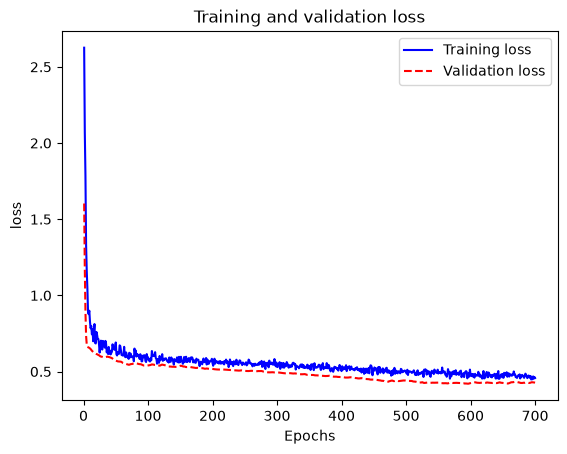

In [23]:
plot_no_dots(history.history['loss'], history.history['val_loss'], 'loss')

In [24]:
#TODO - llamar a evaluate
result = model.evaluate(ds_test)
print(model.metrics_names)
print(result)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - auc_2: 0.7289 - loss: 0.5884
['loss', 'compile_metrics']
[0.5884450078010559, 0.7288516759872437]
